In [70]:
import HST_Calibration as hst
import matplotlib.pyplot as plt
import numpy as np
import importlib
from scipy.ndimage import maximum_filter, gaussian_filter

importlib.reload(hst)

<module 'HST_Calibration' from 'C:\\Users\\thoma\\anaconda_projects\\db\\Spacelab\\HST Assignment\\HST_Calibration.py'>

# HST WFPC2 Calibration

The purpose of this assignment was to take raw WFPC2 exposures and apply the associated calibration files to achieve science-ready images. I have written a Python script called HST_Calibration.py which contains the functions used in calibration and photometry. These are combined into the function `calibrate_exposure()`. The calibrated images are then compared quantitatively to the science-ready images provided.

The calibration follows

$$
\text{stars + noise} = (\text{raw} - \text{bias} - \text{dark}) \times \text{flat} - \text{sky}
$$

where the flat is multiplied rather than divided, as the WFPC2 flat is delivered as an inverse sensitivity.

This function takes the "index" of the exposure (e.g. 2505 for ubai2505m), accesses the raw file and does the following:
1. Mask invalid data with MASKFILE
2. Remove bias level with BLEVFILE
3. Remove bias image with BIASFILE
4. Subtract dark with DARKFILE
5. Flatfield correction with FLATFILE
6. Subtract an estimate of the sky
7. Photometry calibration with the PHOTFLAM and PHOTZPT header keywords

The ADC correction (ATODFILE) is skipped as the raw files are already ADC-corrected, and the shading correction (SHADFILE) is skipped as it is only required for very short exposures. The mask is examined below but is not applied.

I will run the function for each index below, and go into detail afterwards. The astropy warning is caused by a non-standard HISTORY card in the FITS header and can be ignored.

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


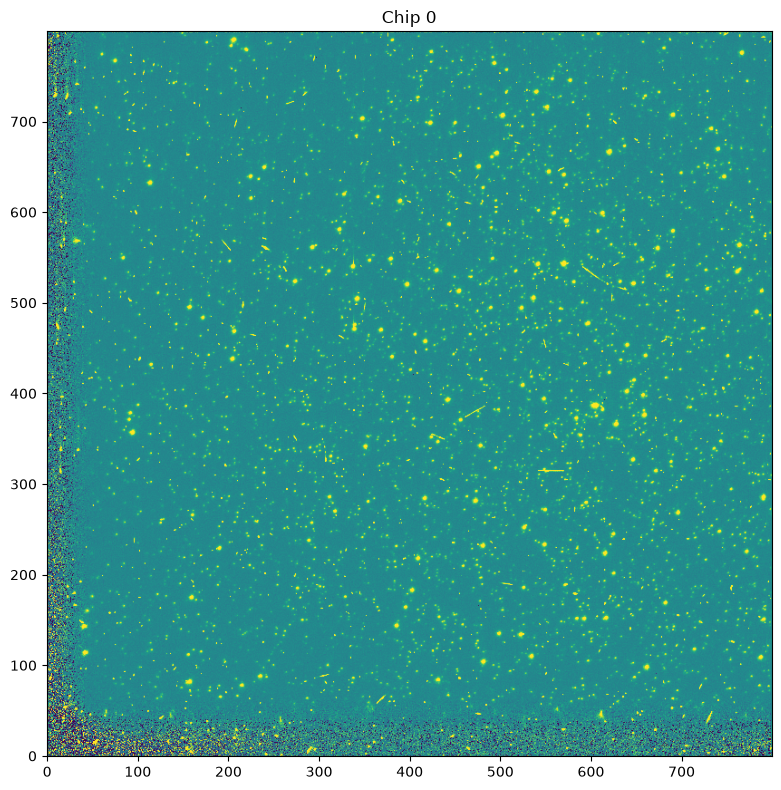

In [43]:
calibrated = hst.calibrate_exposure(2505)
hst.show_chip(calibrated, 0)

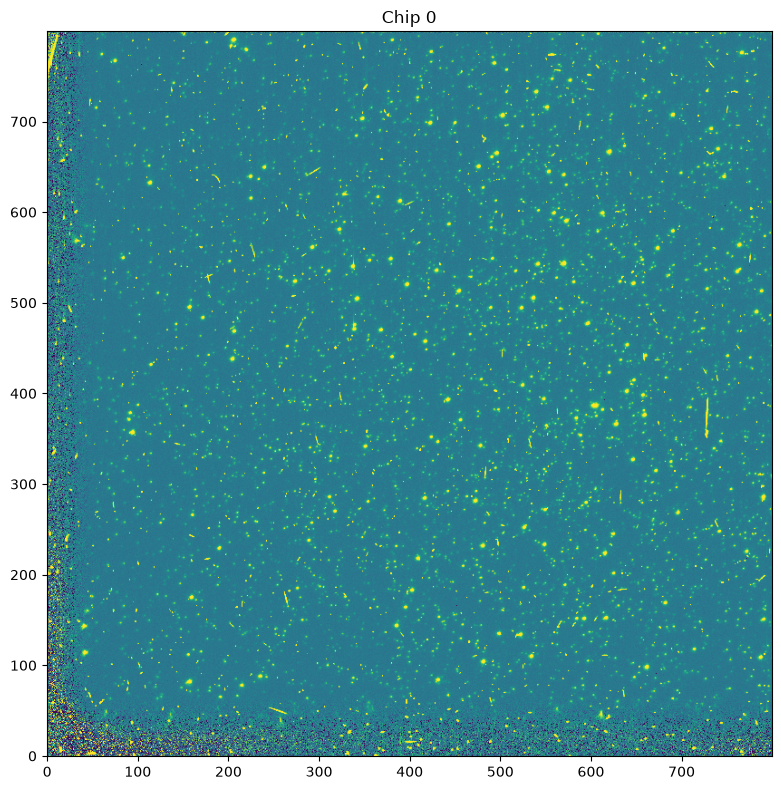

In [44]:
calibrated2 = hst.calibrate_exposure(2507)
hst.show_chip(calibrated2, 0)

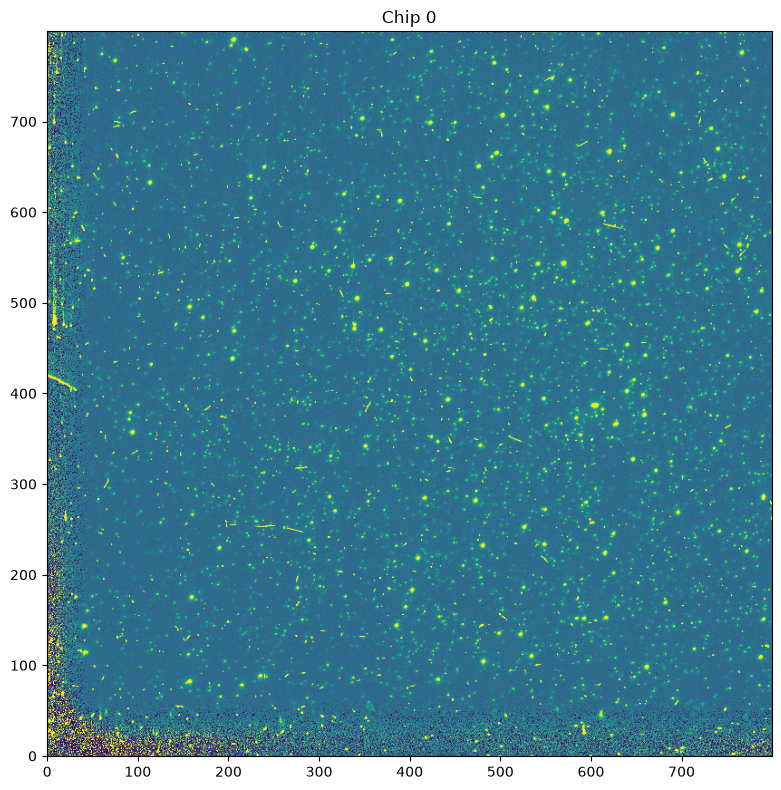

In [45]:
calibrated3 = hst.calibrate_exposure(2508)
hst.show_chip(calibrated3, 0)

We can stack these images and take the median in order to remove cosmic rays. This works because the cosmic rays are not present in every image and so the median value will average them away. This is not the case for defective or hot pixels, which sit at the same position in every exposure and so survive the median. The streaks seen in the individual exposures are gone in the stack, while the bad columns and noisy edges remain.

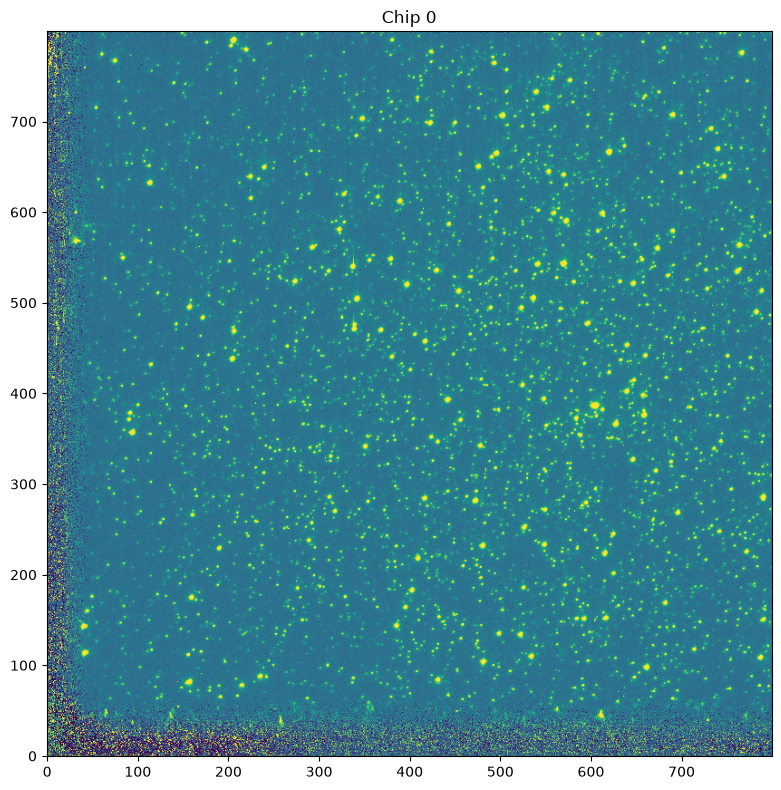

In [46]:
combined_images = hst.cosmic_ray_removal(calibrated,calibrated2,calibrated3,chip=0)

To see what is going on under the hood let's first load and plot the raw file to see what we're working with.

In [47]:
raw_file = hst.load_calibration_files(2505, "raw")
raw = hst.image_extract(raw_file)
print(raw.shape)

(4, 800, 800)


This is a stack of 4 images (one per chip) with a size of 800x800 pixels each. Let's plot them.

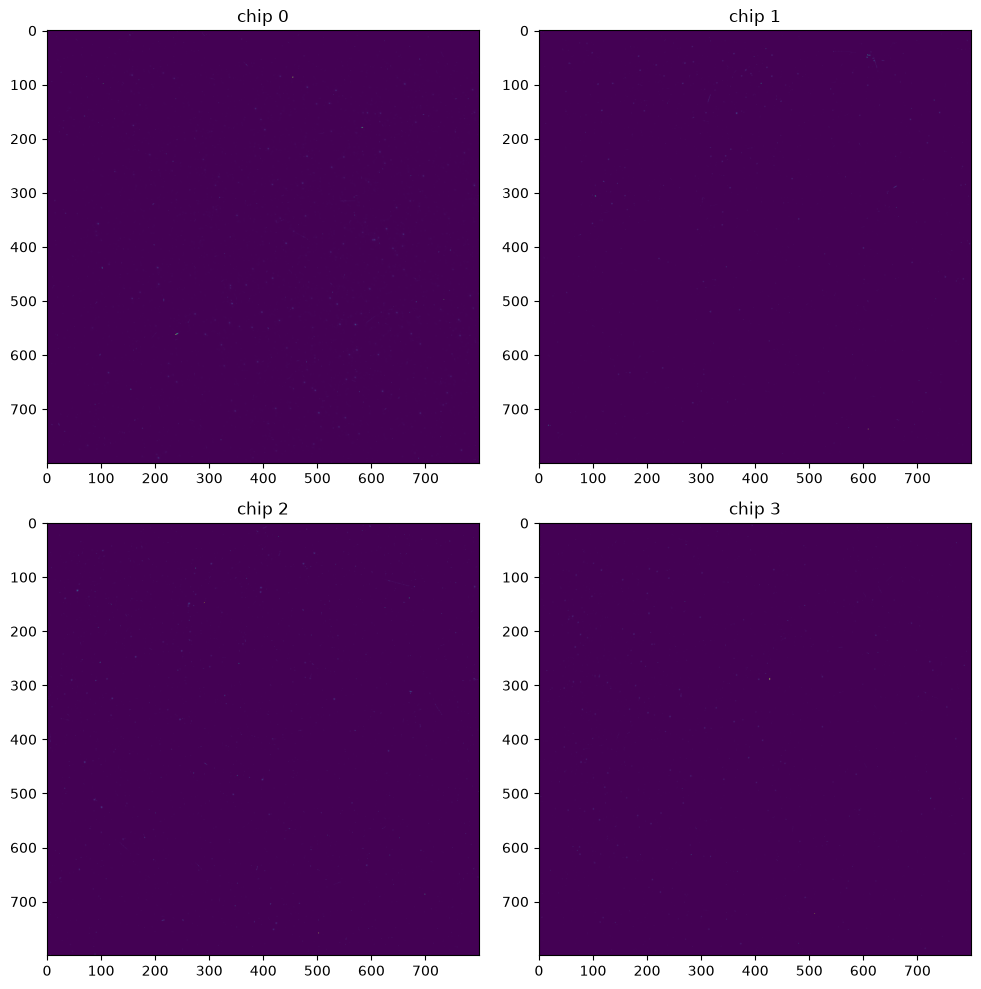

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes_flat = axes.ravel()
for i, ax in enumerate(axes_flat):
  ax.imshow(raw[i])
  ax.set_title(f'chip {i}')
plt.tight_layout()
plt.show()

This is not very helpful. Let's normalise them with a square root transformation. We will normalise using these percentiles (pmin=1, pmax=99) from now on. This is encoded in the show_chip() function.

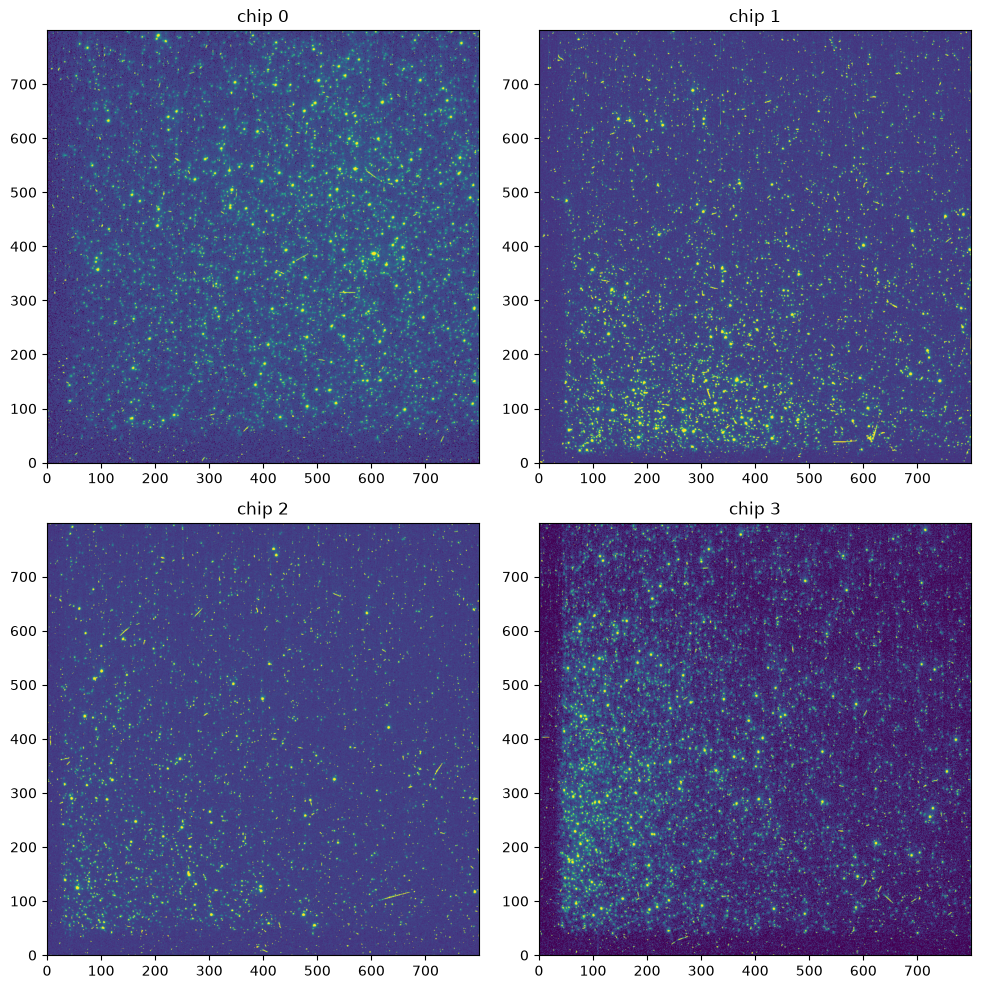

In [49]:
sqrt_raw = hst.transform_by('sqrt', raw, pmin=1, pmax=99)
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes_flat = axes.ravel()
for i, ax in enumerate(axes_flat):
  ax.imshow(sqrt_raw[i], origin = 'lower')
  ax.set_title(f'chip {i}')
plt.tight_layout()
plt.show()

Let's focus on chip 0 for the remainder of our qualitative/comparison plots. The application functions apply the same steps to all chips in the stack, but zeroing in on one chip will focus our attention, as well as help us compare our results to the "science ready" image of chip 0 provided from Hubble.

Let's retrieve and apply the mask file and examine the result.

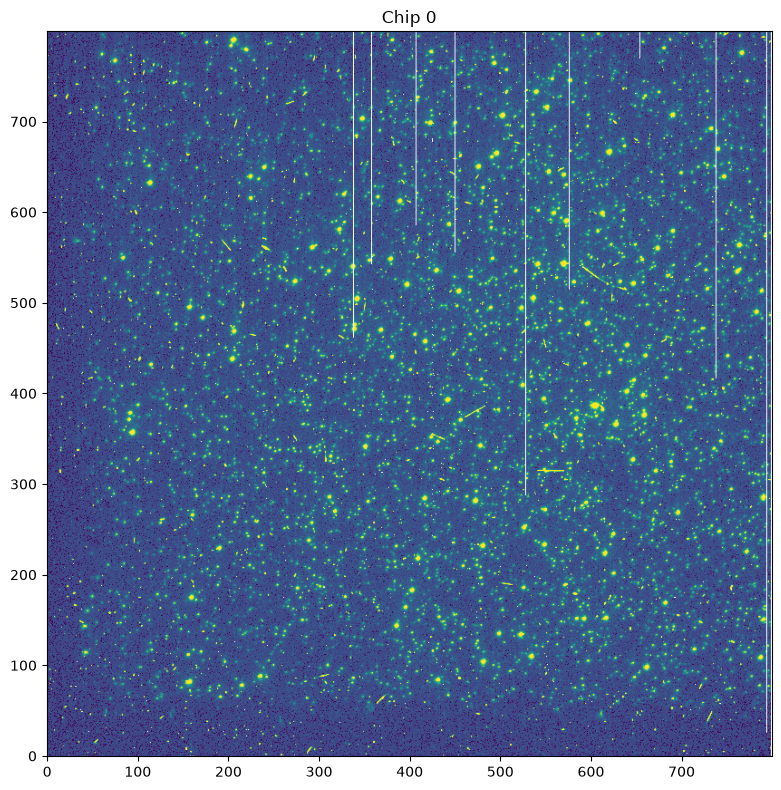

In [50]:
mask_file = hst.load_calibration_files(2505, "mask")
mask = hst.image_extract(mask_file)
masked_image = hst.apply_mask(raw, mask)
hst.show_chip(masked_image, chip=0)

The flagged pixels show up as thin vertical lines, so these are a small number of bad columns rather than pixel overflow. The mask values (0, 2 and 256) are flags rather than data, and applying them produces bright artefacts in the image rather than usable pixel values. The flagged pixels are a very small fraction of the chip, so we will not apply the mask. Let's move on to the blev file.

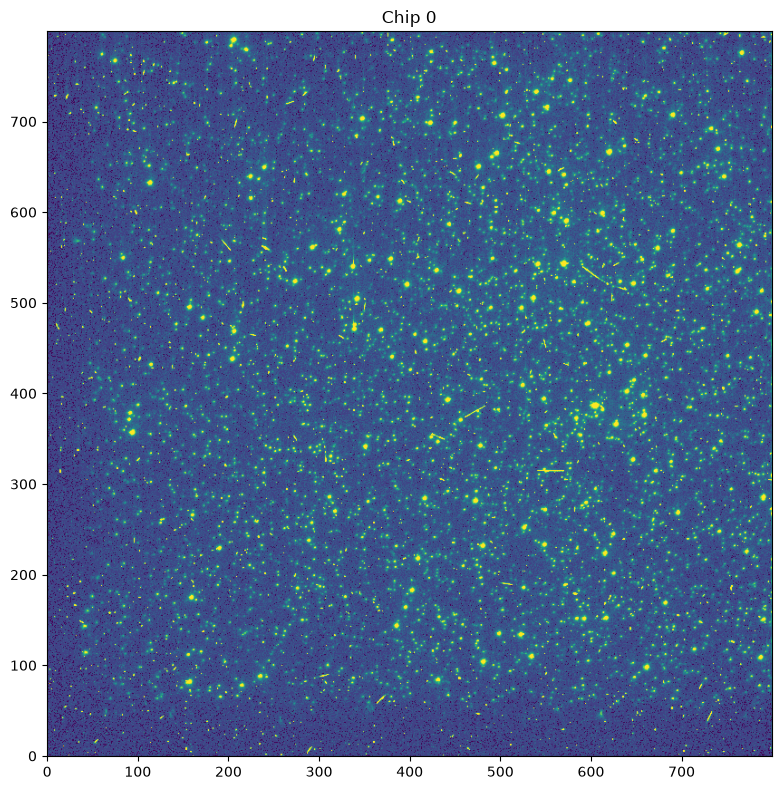

In [51]:
blev_file = hst.load_calibration_files(2505, "blev")
blev_image = hst.apply_blev_correction(raw, blev_file)
hst.show_chip(blev_image, chip=0)

As we can see there is not much difference. The bias level is a DC offset taken from the overscan columns, calculated separately for odd and even columns. It shifts the zero point of the image but does not change its structure. The renormalization hides most of the shift. The correction is therefore only visible in the pixel values, but it is still required so that the later subtractions are made from the correct zero point.

Now let's subtract the bias file. This is an image of the same shape as our science exposure which compensates for readout noise.

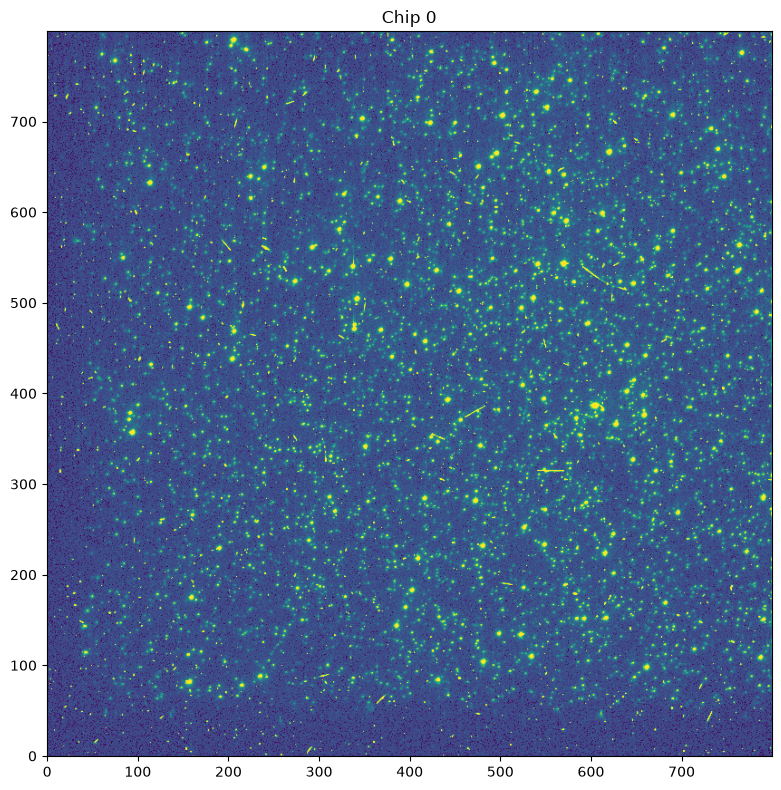

In [52]:
bias_file = hst.load_calibration_files(2505, "bias")
bias = hst.image_extract(bias_file)
bias_image = hst.subtract_bias(blev_image, bias)
hst.show_chip(bias_image, chip=0)

Again not much of a difference. This is an image of the same shape as our science exposure which compensates for readout noise. We get it just by taking a short exposure with a closed shutter. We can simply subtract this from our bias level corrected image. Like the bias level, its effect is mostly on the zero level and the faint background.

Let's move on to the dark file. This is a closed-shutter image with same exposure time as our science image, and it accounts for thermal noise.

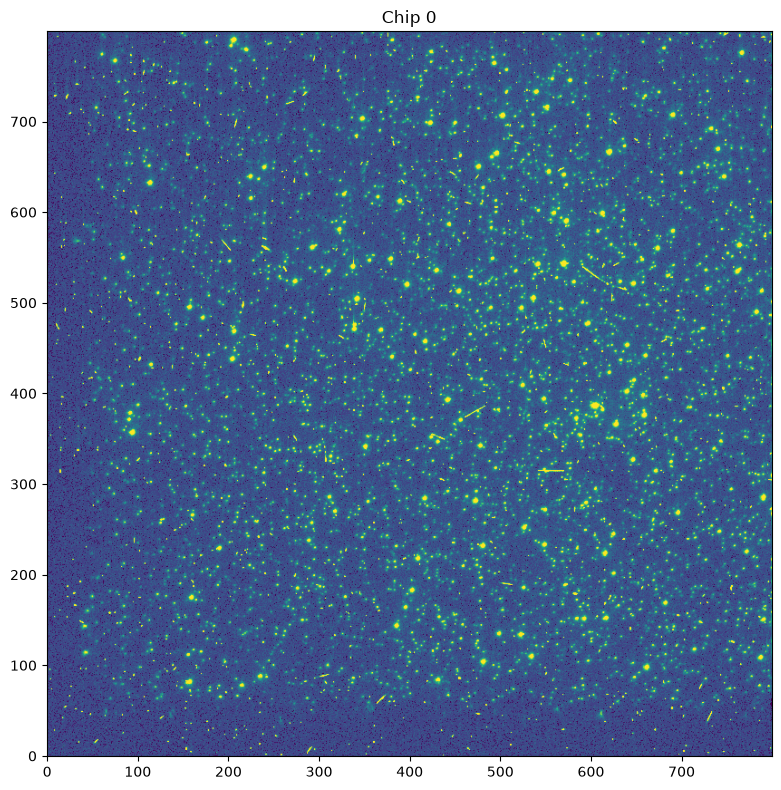

In [53]:
dark_file = hst.load_calibration_files(2505, "dark")
dark = hst.image_extract(dark_file)
dark_image = hst.subtract_dark(bias_image,  dark, raw_file)
hst.show_chip(dark_image, chip=0)

Again not much change. Let's apply the flat file. This is an image taken with a uniform exposure that accounts for pixel sensitivity variations across our detector. The WFPC2 pipeline delivers this as an inverse sensitivity, so we multiply this by our image in the reduction workflow as opposed to dividing by it.

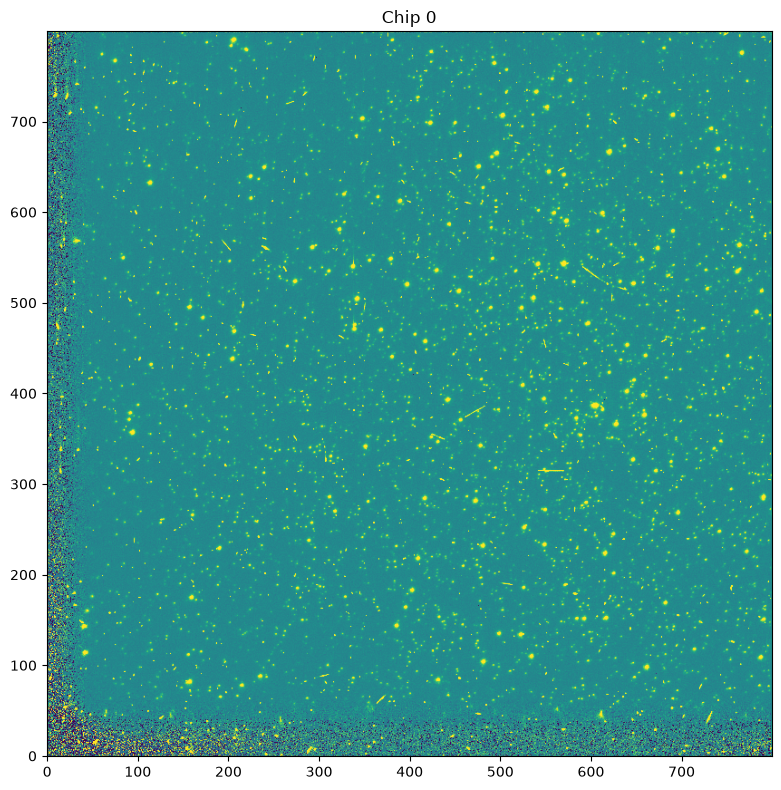

In [54]:
flat_file = hst.load_calibration_files(2505, "flat")
flat = hst.image_extract(flat_file)
flat_image = hst.apply_flat(dark_image, flat)
hst.show_chip(flat_image, chip=0)

This makes much more of a difference. The flat removes pixel-to-pixel sensitivity variations. The background is noticeably more uniform. It also reveals a band of roughly 40 pixels along the left and bottom edges of the chip where the noise is much higher. These edge artifacts will be cropped/ignored for the following photometry comparisons.

Finally we must subtract an estimate of the background/sky contribution. Here we can use Median Absolute Deviation clipping or MAD clipping.
With the MAD our standard deviation can be approximated with

$$
\sigma_{\mathrm{std}} \approx 1.4826 \times \mathrm{MAD}
$$

Then we simply filter our data based on how much of the data is greater than so many standard deviations above the background. Here we will use 3 standard deviations.

Experiments with splitting the masked image into boxes and finding the median within each box were done using the photutils module. This revealed that the best box was actually the size of the image itself, so a global median of the masked image was adopted in the get_sky() function. This suggests there is no significant sky gradient across the chip, and in a crowded field smaller boxes are more likely to be biased by the stars within them.

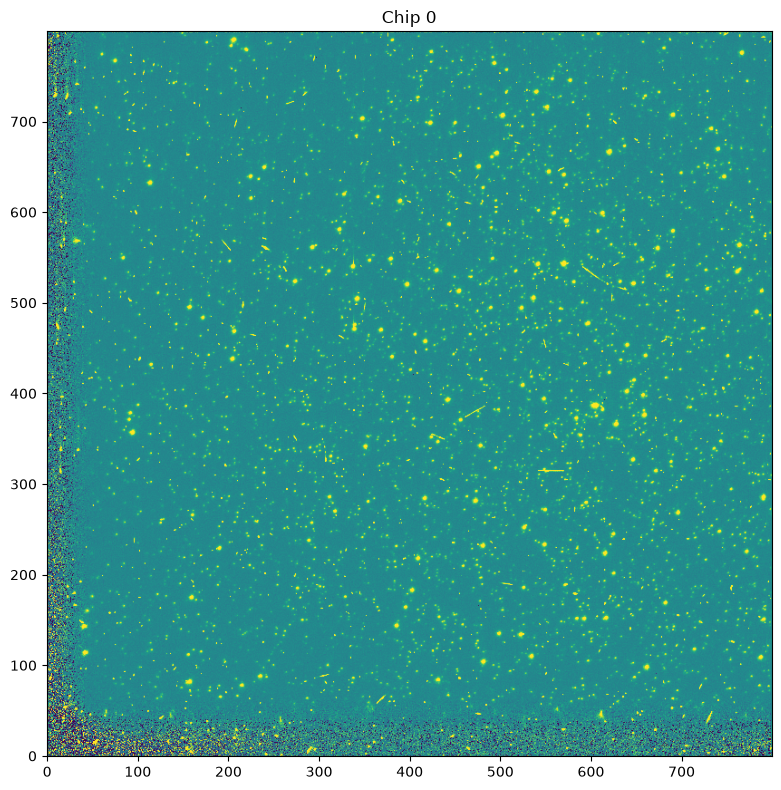

In [55]:
sky = hst.get_sky(raw)
sky_image = flat_image.copy()
for chip in range(flat_image.shape[0]):
    sky_image[chip] -= sky[chip]
hst.show_chip(sky_image, chip=0)


## Quantitative Analysis


Now that we have a fully calibrated image, let's compare it to the "science ready" image provided. The difference image is our calibrated image minus the science-ready image.

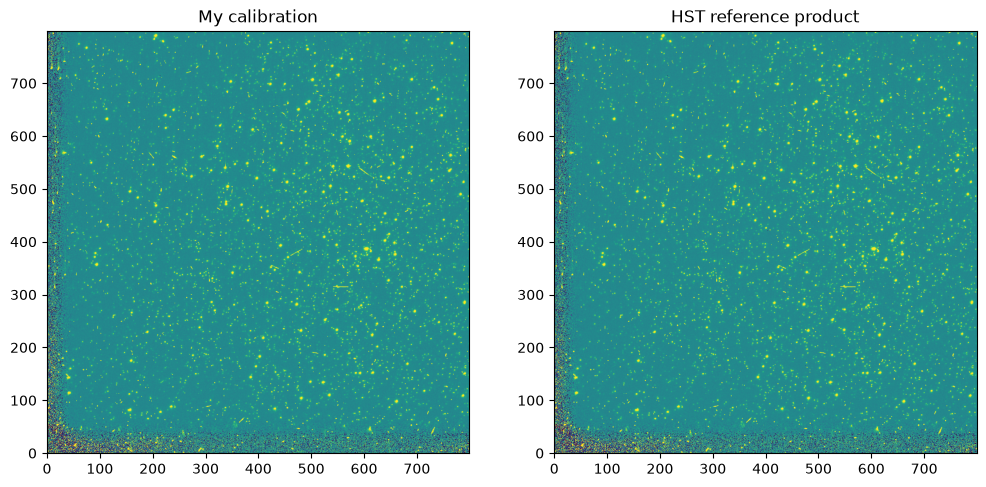

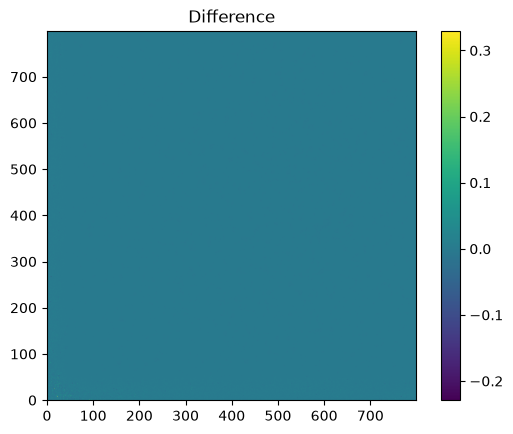

In [58]:
difference = hst.difference(calibrated,2505, 0)

The difference is minimal visually. Let's explore further.

We can compare the histograms of each image for a better quantitative analysis.

In [1]:
hst.histogram_overlay(calibrated[0], 2505)

NameError: name 'hst' is not defined

The two histograms overlap almost exactly. Both peak at zero as the sky has been subtracted, and both have the same extended tail of pixels on stars. There are small deviations in the 1000-2000 range. These bins contain only a handful of pixels (note the logarithmic scale), so small differences from our sky estimate or from rounding in the pipeline can move a pixel from one bin to the next.

We can also compare the magnitudes of stars in each image. If the calibrated image is very close to the science ready one we should expect similar photometry results.

To do this we can use aperture photometry. We use the median-combined image to remove the cosmic rays, crop the image so that we ignore the edge artifacts present, and identify the 100 brightest stars in the image. We then measure the flux of each star candidate and compare between images. We define $\Delta m = m_{\mathrm{mine}} - m_{\mathrm{ref}}$, so a positive $\Delta m$ means our star is fainter than the reference. The first method fits a circular aperture of fixed radius (5 pixels) around each star.

Found 2367 candidate sources
Keeping 100 brightest sources


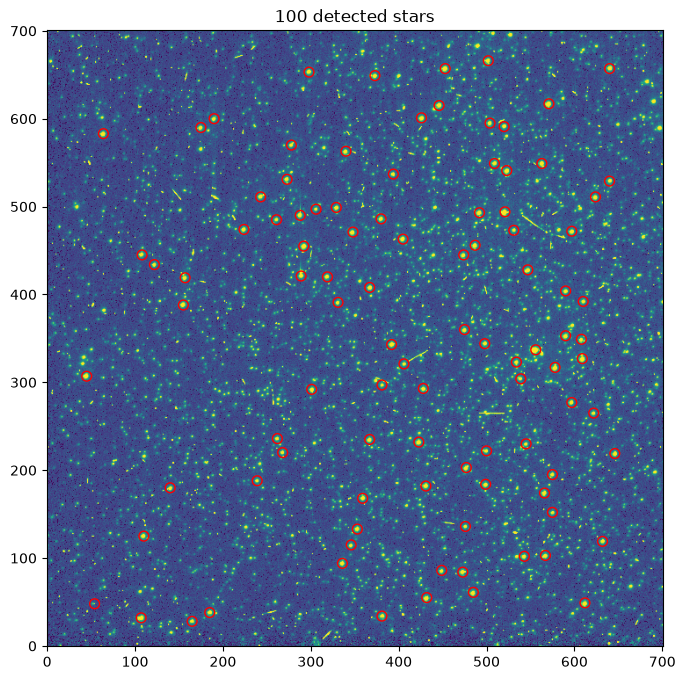

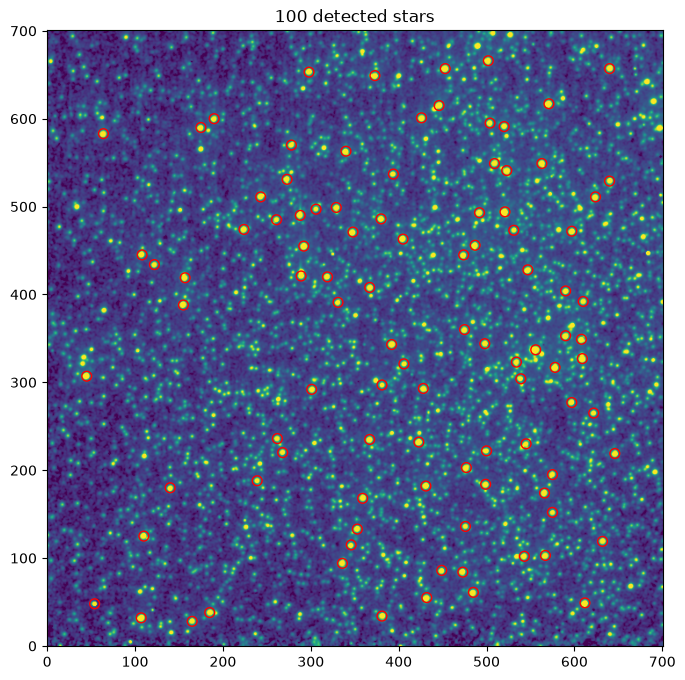

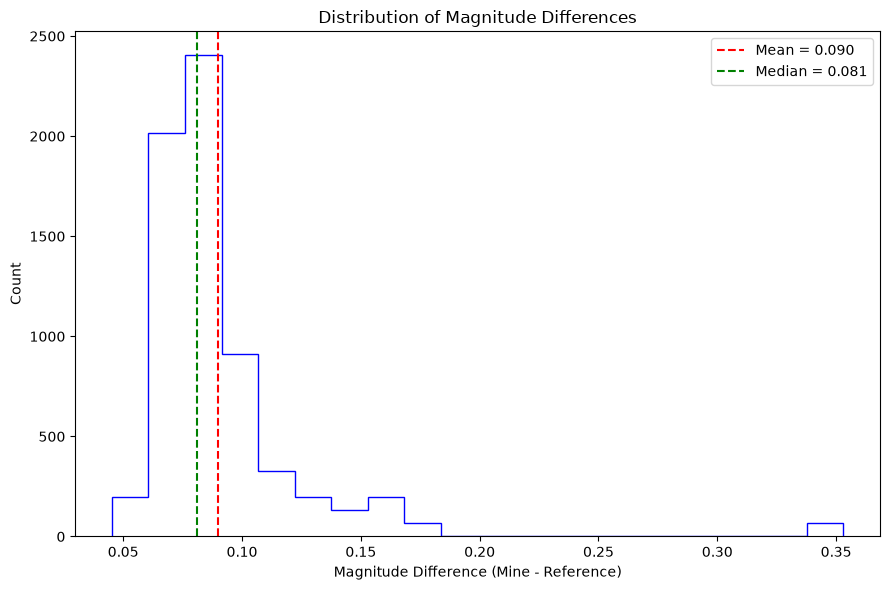

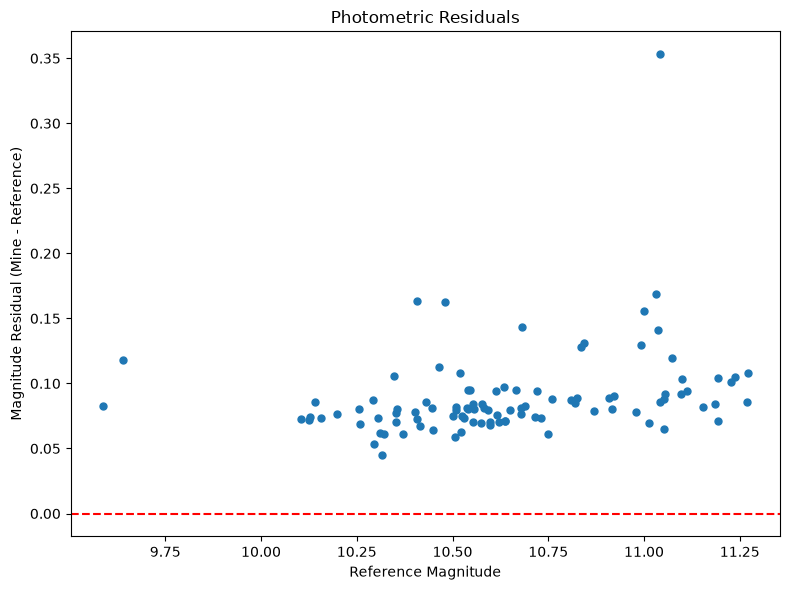

Worst residual: 0.35306169502291596
My mag: 11.393559280477636
Ref mag: 11.04049758545472
Coord: [297 381]


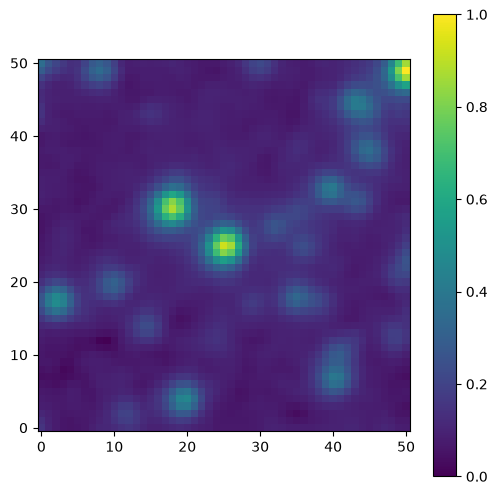


Photometric Comparison
----------------------
Mean Δm: 0.08985115123556238
Median Δm: 0.08125586641233085
Std Δm: 0.03530933348901635


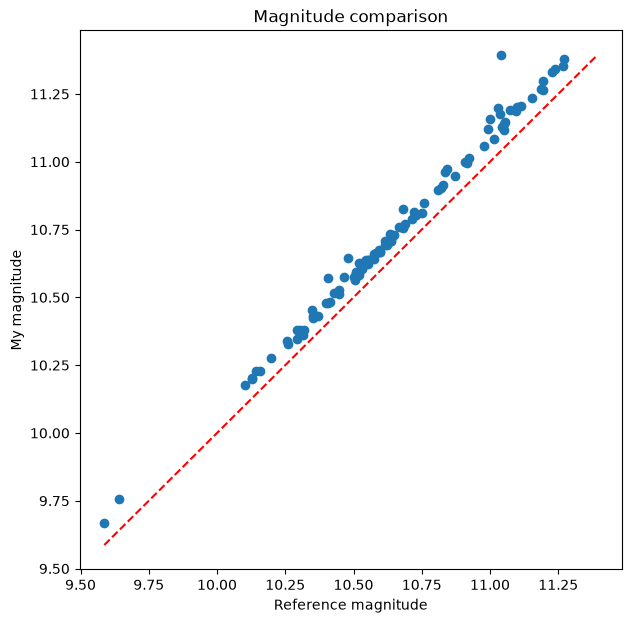

In [72]:
no_edge = hst.square_aperture(combined_images[0], center=[400, 400], box_size=700)
gf_image = gaussian_filter(no_edge, sigma=1)
hst.compare_magnitudes(gf_image, 2505, chip=0, radius=5, max_sources=100, box_size=700, photometry ="aperture")

As we can see our magnitudes are fairly correlated with the reference, but they are systematically fainter. The mean $\Delta m$ is 0.090 (median 0.081, $\sigma$ = 0.035), and every residual is positive, so this is a bias rather than random scatter. This is because we have naively chosen to sum up all the flux within a set radius of the source. A fixed radius cuts off the wings of the stellar profile, so the flux outside the aperture is lost. The offset is roughly constant with magnitude, increasing slightly for the fainter stars. The worst residual (0.35 mag at [297 381]) is an isolated outlier, likely contaminated by a neighbouring source.

We can improve our estimations by fitting a 2D gaussian to each source and setting the aperture size from the fit. The 2D gaussian tails off to zero, and an aperture 3 standard deviations from the peak encloses about 99% of its flux. The aperture will now scale with the width of each star instead of being fixed.

Found 2367 candidate sources
Keeping 100 brightest sources


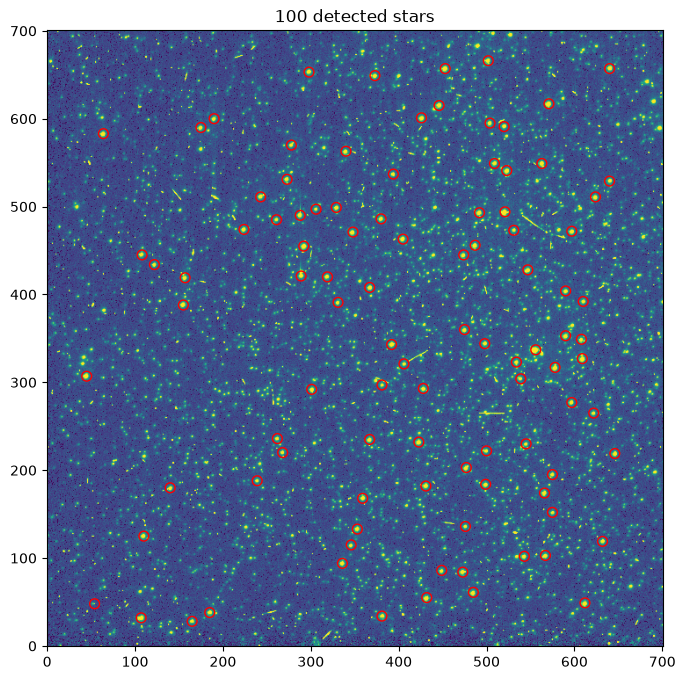

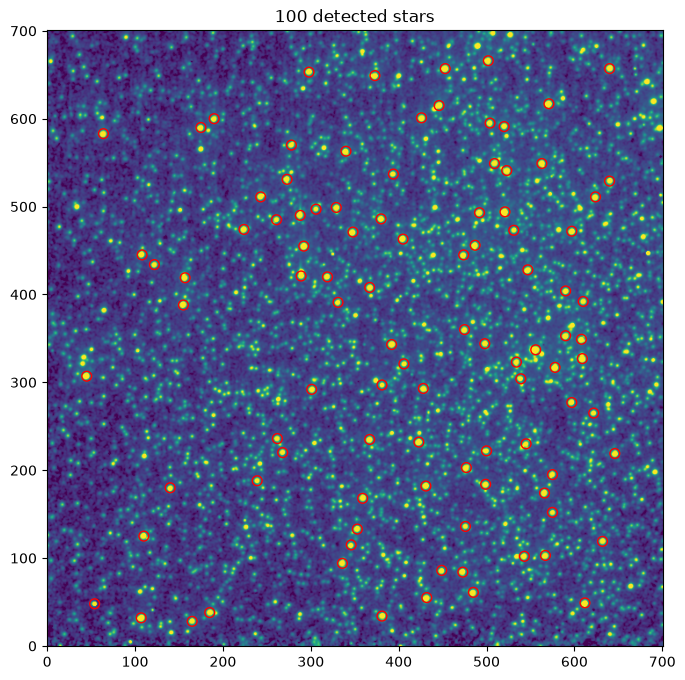

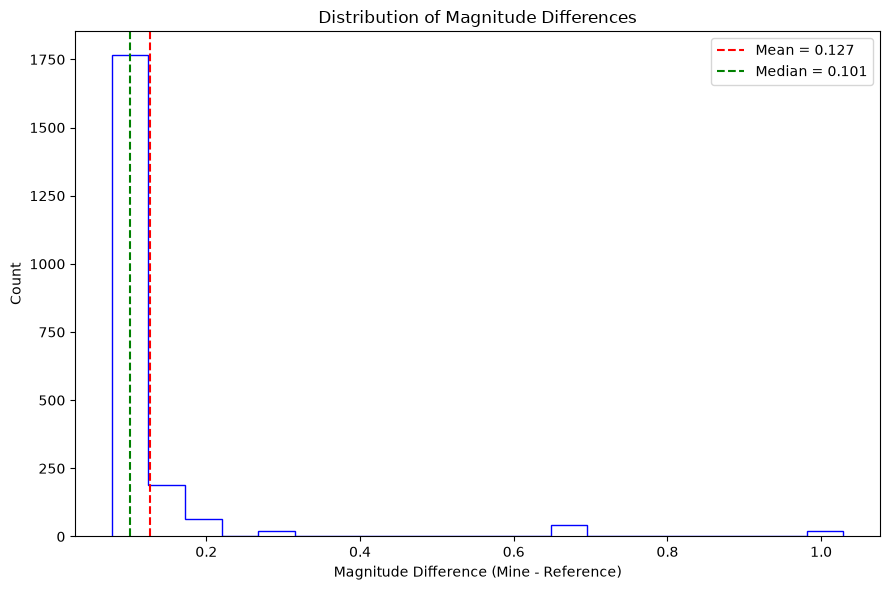

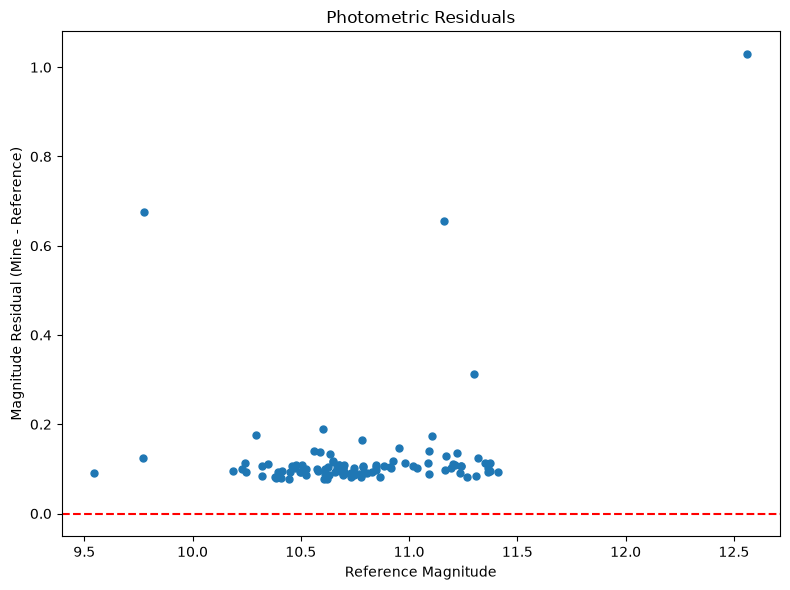

Worst residual: 1.0290006529760234
My mag: 13.59104262569311
Ref mag: 12.562041972717086
Coord: [445 474]


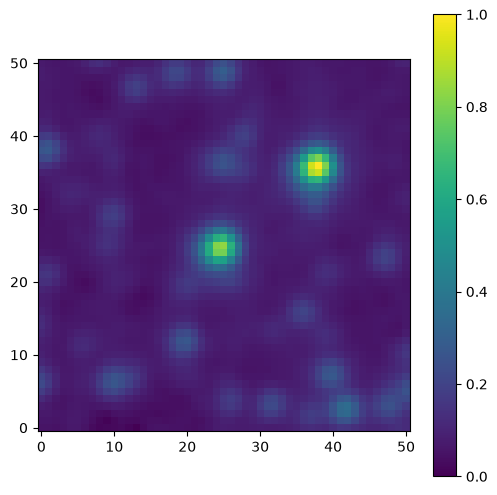


Photometric Comparison
----------------------
Mean Δm: 0.12692616497867334
Median Δm: 0.1011707891331497
Std Δm: 0.12328268508342267


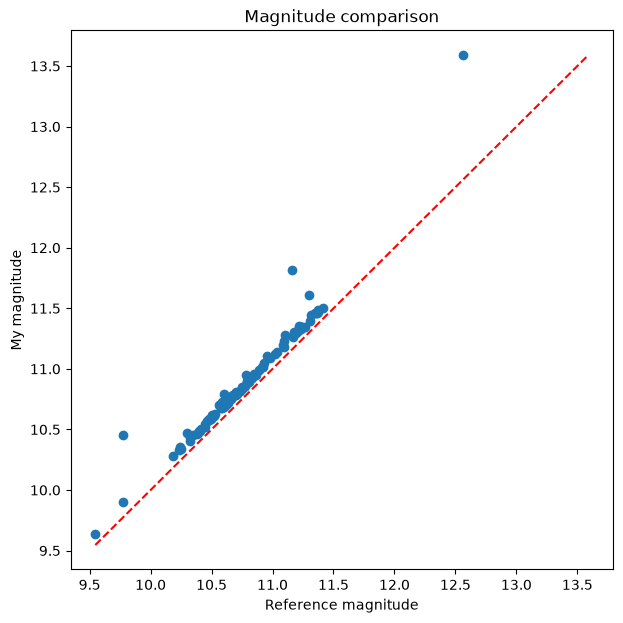

In [73]:
hst.compare_magnitudes(gf_image, 2505, chip=0, radius=5, max_sources=100, box_size=700, photometry ="psf_aperture")

The bulk of the stars now follow the 1:1 line more closely and have less scatter, with residuals clustered between about 0.08 and 0.12 mag. However the summary statistics are not better than the fixed aperture: the mean $\Delta m$ is 0.127 (median 0.101, $\sigma$ = 0.123). A few sources have very large residuals, up to 1.03 mag at [445 474], which inflate the mean and standard deviation. These are likely poor fits where a star is blended with its neighbours in this crowded field, so the 3$\sigma$ aperture is the wrong size. The 3$\sigma$ aperture also still cuts off the wings of the profile, so the systematic offset is not removed.

We can improve this further by fitting our 2D gaussian and integrating under the curve. This is a known result with

$$
F = \iint_{-\infty}^{+\infty} G(x,y)\,dx\,dy = 2\pi A \sigma_x \sigma_y
$$

where $A$ is the fitted amplitude and $\sigma_x$, $\sigma_y$ are the fitted widths. This includes the wings that a finite aperture cuts off and does not depend on a chosen radius. The fit is also done on the unsmoothed image, so the smoothing does not bias the fitted widths. This gives more source candidates (3140 compared to 2367) as the peaks are not smoothed away.

Found 3140 candidate sources
Keeping 100 brightest sources


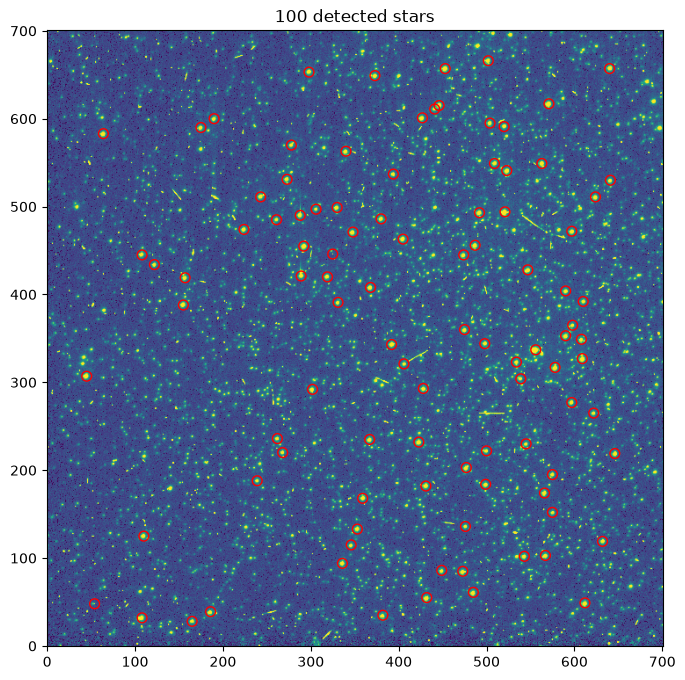

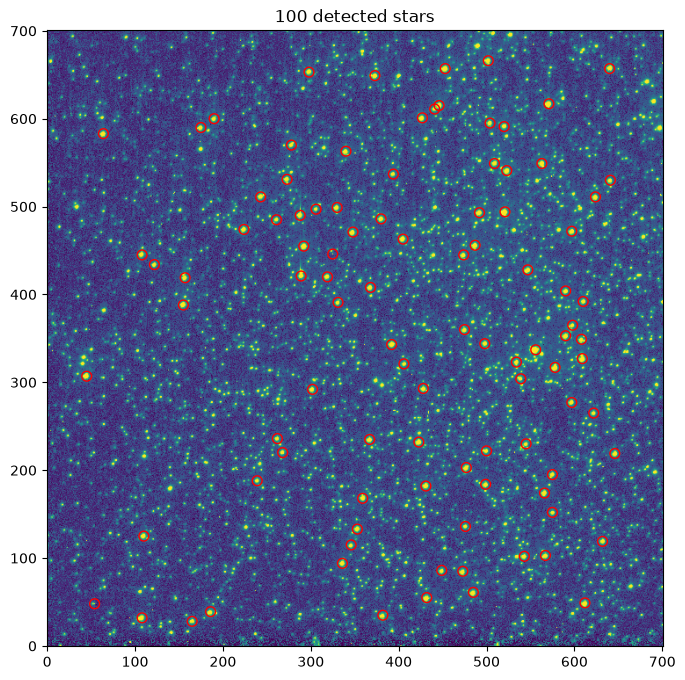

Failed fit (446, 325)
Failed fit (365, 598)


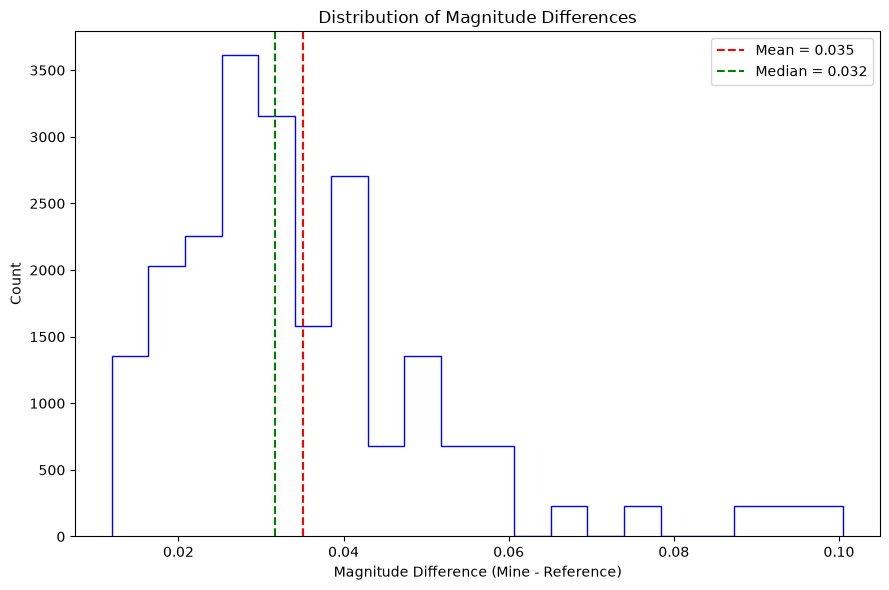

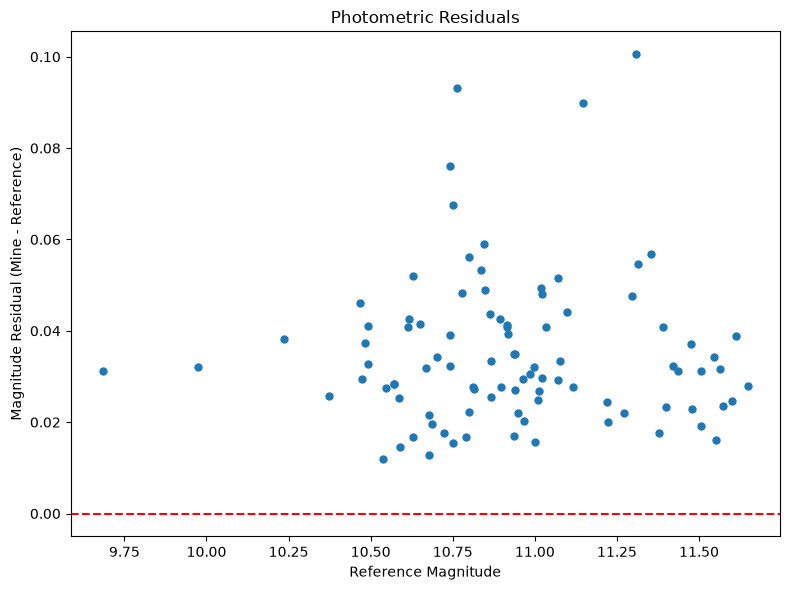

Worst residual: 0.10053871171718498
My mag: 11.409027511055132
Ref mag: 11.308488799337947
Coord: [570 278]


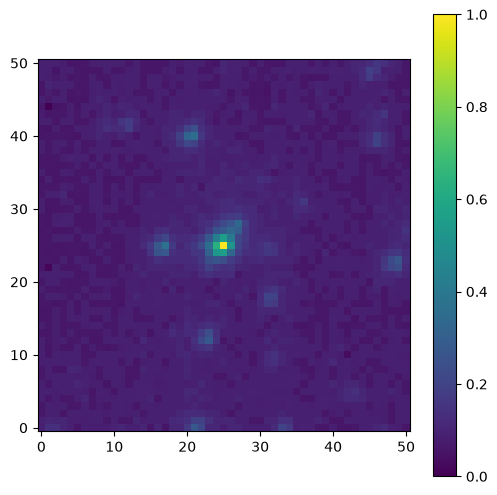


Photometric Comparison
----------------------
Mean Δm: 0.035078752918896866
Median Δm: 0.03169494808273399
Std Δm: 0.016445054175531947


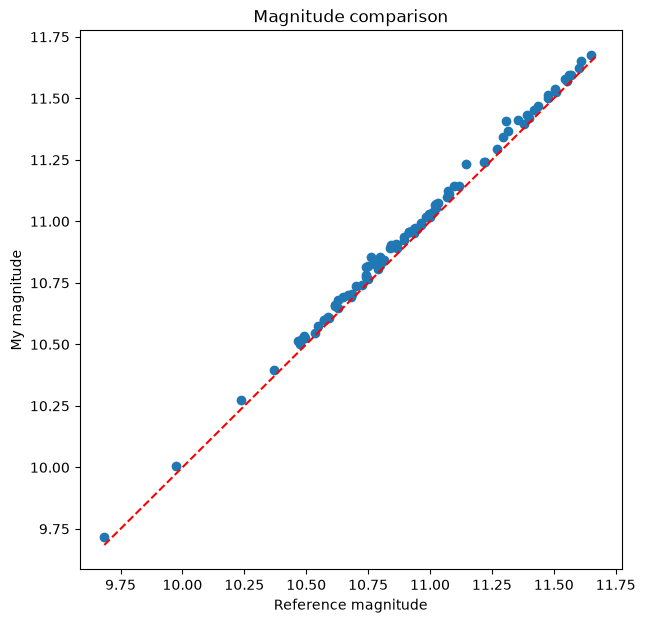

In [75]:
hst.compare_magnitudes(no_edge, 2505, chip=0, radius=5, max_sources=100, box_size=700, photometry ="gaussian")

The gaussian integration gives the best agreement with the reference. The mean $\Delta m$ is 0.035 and all residuals are below about 0.1 mag, and there are no large outliers. Two sources failed to fit and were discarded. The remaining small positive offset is likely because a single gaussian does not capture the extended wings of the WFPC2 PSF, with a small contribution from differences in the sky estimate.

| Method | Mean $\Delta m$ | Median $\Delta m$ | $\sigma$ |
|---|---|---|---|
| Aperture (r = 5 px) | 0.090 | 0.081 | 0.035 |
| Gaussian 3$\sigma$ aperture | 0.127 | 0.101 | 0.123 |
| Gaussian integration | 0.035 | 0.032 | 0.016 |

## Conclusion

The calibration routine reproduces the science-ready image closely. The difference image is within about 0.3 of the image units against stellar peaks of order $10^4$, and the pixel histograms are nearly identical. The flat field had the largest visible effect, while the bias level, bias image and dark have a small effect on a percentile stretch but are needed to set the correct zero point. The photometry agrees to within 0.035 mag when integrating a fitted gaussian, and the choice of method matters more than the calibration: fixed apertures lose 7-8% of the flux.

The main limitations are:
- A single global sky value was used, which assumes the sky is flat across the chip.
- The mask was not applied, so the bad columns remain in the data.
- The edges of the chip are noisy after flat fielding and were cropped for the photometry.